!# Atomistic spin dynamics quickstart
Build a model Hamiltonian, relax a skyrmion lattice with the LLG equation and compute its topological charge.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from magex.models import write_model
from magex.spinmodel import load_results, SpinSystem
from magex.llg import LLGSolver
from magex import texture
write_model("tri.json", lattice="triangular", a=3.0, J=[2.0], D=1.0, moment=3.0)
uc = load_results("tri.json")
sys = SpinSystem(uc, (36, 36, 1), (True, True, False), field=(0, 0, 2.0))
print(sys.summary())

spin model: 1 magnetic sites/cell (X), moments [3.0] mu_B, reference = ferromagnet
  couplings: J = mft, rcut = 6.000 A (NN 3.000 A), 1 shells, 6 couplings/cell, 100.0% of J(q=0) retained
  supercell (36, 36, 1), pbc (True, True, False): N = 1296 spins, nnz = 49248
  single-ion anisotropy: off;  field B = [0.0, 0.0, 2.0] T


In [2]:
e = sys.init_spins("random", seed=1)
llg = LLGSolver(sys, alpha=0.5, dt=2e-3, temperature=20.0, seed=1)
e, _, _ = llg.run(e, 3000, output_every=500)      # anneal at 20 K
llg.T = 0.0
e, table, _ = llg.run(e, 6000, output_every=500)
print("topological charge Q =", round(texture.topological_charge(sys, e), 3))

topological charge Q = -3.0


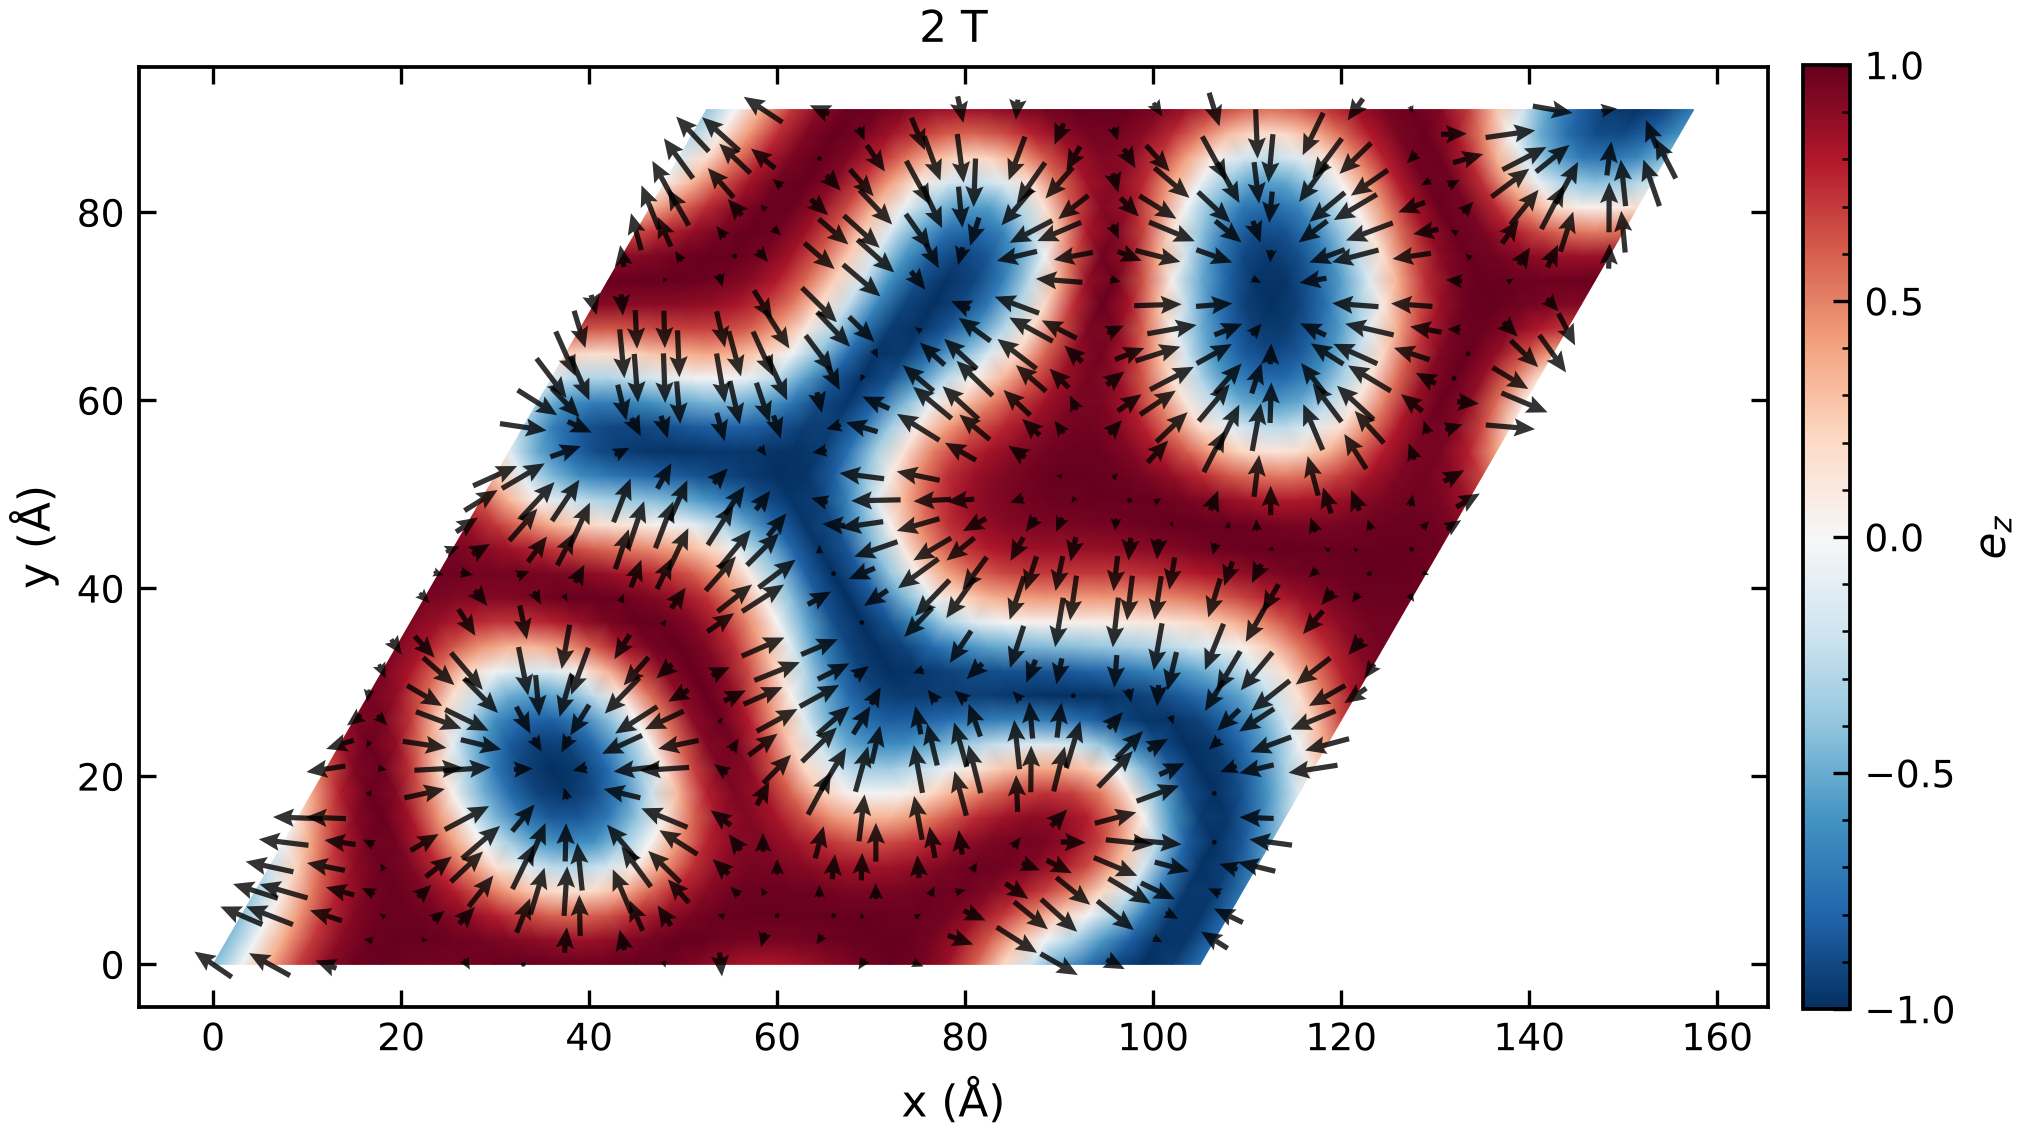

In [3]:
texture.plot_texture(sys, e, "skyrmions.png", title="2 T")
from IPython.display import Image; Image("skyrmions.png", width=520)